# Question 7: Forecast August 2026 activity

County-level forecasts for households (the visits proxy), pounds and individuals, plus the graduate addendum forecasts for children, adults and seniors. The reproducible forecasting logic lives in `questions/q7_forecast_august/analysis.py`; this notebook runs it and explores its diagnostics and results.

> **Hard cutoff:** August 2026 data from any source is prohibited. The only permissible forecast input ends in July 2026. Do not search for or load August 2026 actuals.

## Setup and leakage guard

The notebook locates the repository root from the current directory, loads the canonical processed county-month panel, checks the hard cutoff, and then runs the same script used to generate the saved tables. Backtests use August 2023, 2024 and 2025, each using only observations strictly before its target month.

In [1]:
from pathlib import Path
import sys

ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "src" / "qkit.py").exists()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not locate repository root containing src/qkit.py")

sys.path.insert(0, str(ROOT / "src"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import config as cfg
import qkit

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
print(f"Repository: {ROOT}")
print(f"Permitted training cutoff: {cfg.TRAIN_CUTOFF_YM}")
print(f"Forecast target (not observed): {cfg.FORECAST_TARGET_YM}")

Repository: /Users/uddam/copilot-worktrees/MinneMUDAC/uddamchea-stunning-spork
Permitted training cutoff: 202607
Forecast target (not observed): 202608


In [2]:
panel = qkit.county_month()
qkit.leakage_check(panel)
panel = panel.loc[panel["yearmonth"].le(cfg.TRAIN_CUTOFF_YM)].copy()
if panel["yearmonth"].max() != cfg.TRAIN_CUTOFF_YM:
    raise ValueError("Expected the permitted panel to end in July 2026")

display(pd.DataFrame({
    "rows": [len(panel)],
    "counties_with_reporting_history": [panel["fips"].nunique()],
    "months": [panel["yearmonth"].nunique()],
    "first_month": [panel["yearmonth"].min()],
    "last_permitted_month": [panel["yearmonth"].max()],
    "July 2026 reporting sites (statewide sum)": [panel.loc[panel.yearmonth.eq(cfg.TRAIN_CUTOFF_YM), "n_sites_reporting"].sum()],
}))

leakage_check passed: nothing at or after 202608


,rows,counties_with_reporting_history,months,first_month,last_permitted_month,July 2026 reporting sites (statewide sum)
0,4730,86,55,202201,202607,488


## Exploratory analysis: understand the panel before forecasting

Start by checking the panel's coverage and reporting completeness, then inspect statewide trends and county-level August/July variation. These are descriptive checks—not forecasts—and all calculations use the cutoff-filtered `panel` created above. No data from August 2026 or later is used.

In [3]:
metrics = [*cfg.THREE_METRICS, *cfg.AGE_METRICS]

coverage = pd.DataFrame({
    "rows": [len(panel)],
    "distinct_counties": [panel.fips.nunique()],
    "distinct_months": [panel.yearmonth.nunique()],
    "missing_county_months_vs_87_counties": [87 * panel.yearmonth.nunique() - len(panel)],
    "first_yearmonth": [panel.yearmonth.min()],
    "last_yearmonth": [panel.yearmonth.max()],
})
quality = pd.DataFrame({
    "missing_values": panel[metrics + ["n_sites_reporting"]].isna().sum(),
    "zero_values": panel[metrics + ["n_sites_reporting"]].eq(0).sum(),
    "minimum": panel[metrics + ["n_sites_reporting"]].min(),
})
display(coverage)
display(quality)

# Counties absent from the activity panel are reporting gaps, not observed zeroes.
reference = qkit.mmg(years=[2024])[['fips', 'county_name']].drop_duplicates()
reference['fips'] = reference.fips.astype('string').str.zfill(5)
observed_fips = set(panel.fips.astype('string').str.zfill(5))
no_activity = reference.loc[~reference.fips.isin(observed_fips)]
display(no_activity)

,rows,distinct_counties,distinct_months,missing_county_months_vs_87_counties,first_yearmonth,last_yearmonth
0,4730,86,55,55,202201,202607


,missing_values,zero_values,minimum
households,0,10,0.0
pounds,0,10,0.0
individuals,0,9,0.0
children,0,9,0.0
adults,0,9,0.0
seniors,0,9,0.0
n_sites_reporting,0,0,1.0


,fips,county_name
518,27167,Wilkin


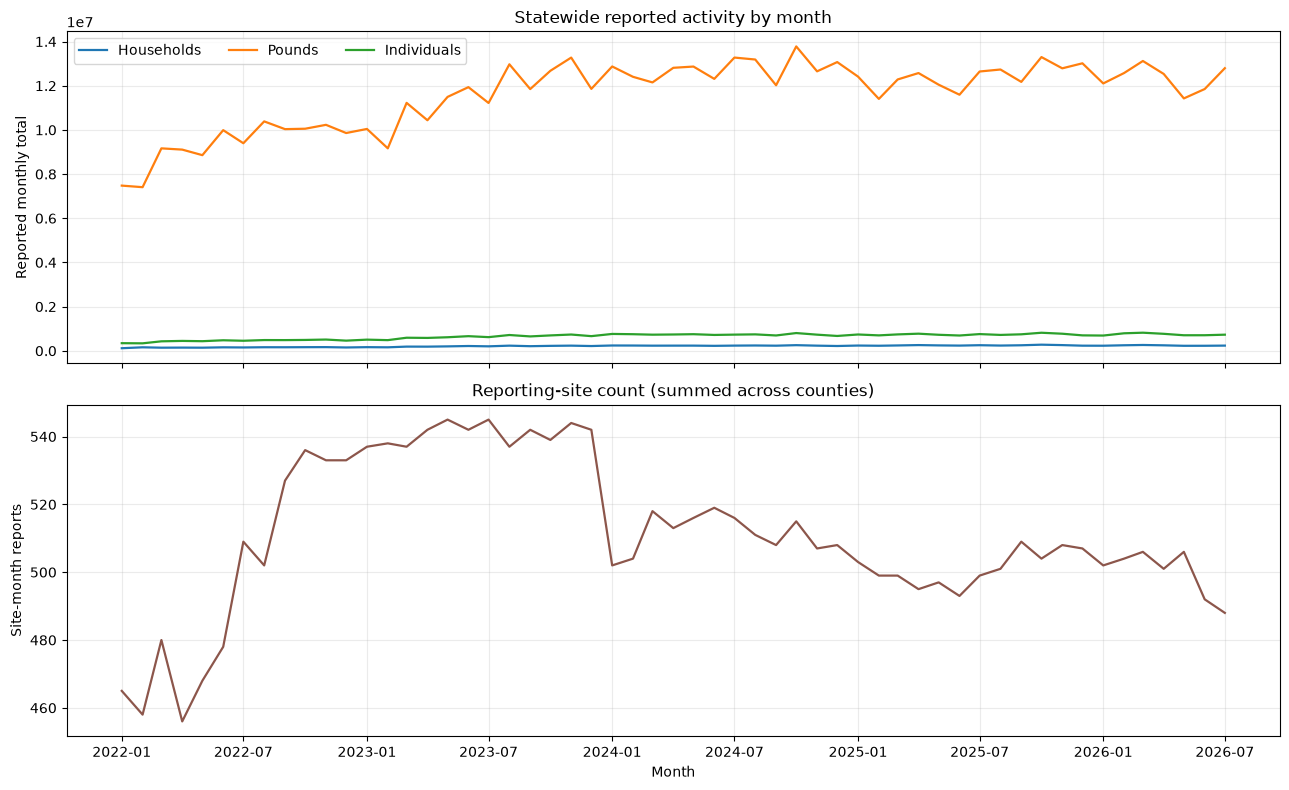

July 2026 reporting sites: 488; previous 11-month average: 503.6; difference: -3.1%


In [4]:
# Statewide totals by month, using county-month observations through July 2026 only.
state_monthly = (panel.groupby(["yearmonth", "date"], as_index=False)[metrics + ["n_sites_reporting"]]
                 .sum().sort_values("yearmonth"))
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for metric in cfg.THREE_METRICS:
    axes[0].plot(state_monthly.date, state_monthly[metric], label=metric.title(), linewidth=1.6)
axes[0].set(title="Statewide reported activity by month", ylabel="Reported monthly total")
axes[0].legend(ncol=3)
axes[0].grid(alpha=0.25)
axes[1].plot(state_monthly.date, state_monthly.n_sites_reporting, color="#8c564b", linewidth=1.6)
axes[1].set(title="Reporting-site count (summed across counties)", ylabel="Site-month reports", xlabel="Month")
axes[1].grid(alpha=0.25)
fig.tight_layout()
plt.show()

# Compare the final permitted month with recent reporting-site history.
latest_sites = state_monthly.loc[state_monthly.yearmonth.eq(cfg.TRAIN_CUTOFF_YM), "n_sites_reporting"].iloc[0]
trailing_sites = state_monthly.loc[state_monthly.yearmonth.between(202508, 202606), "n_sites_reporting"].mean()
print(f"July 2026 reporting sites: {latest_sites:,.0f}; previous 11-month average: {trailing_sites:,.1f}; difference: {100 * (latest_sites / trailing_sites - 1):+.1f}%")

,year,metric,counties,median_ratio,q10_ratio,q90_ratio
0,2022,households,86,1.051,0.826,1.215
1,2022,pounds,86,1.072,0.818,1.292
2,2022,individuals,86,1.035,0.823,1.151
6,2023,households,86,1.075,0.916,1.260
7,2023,pounds,86,1.145,0.974,1.320
8,2023,individuals,86,1.072,0.926,1.321
12,2024,households,85,0.985,0.850,1.184
13,2024,pounds,85,0.985,0.830,1.195
14,2024,individuals,85,0.956,0.748,1.153
18,2025,households,86,0.930,0.815,1.114


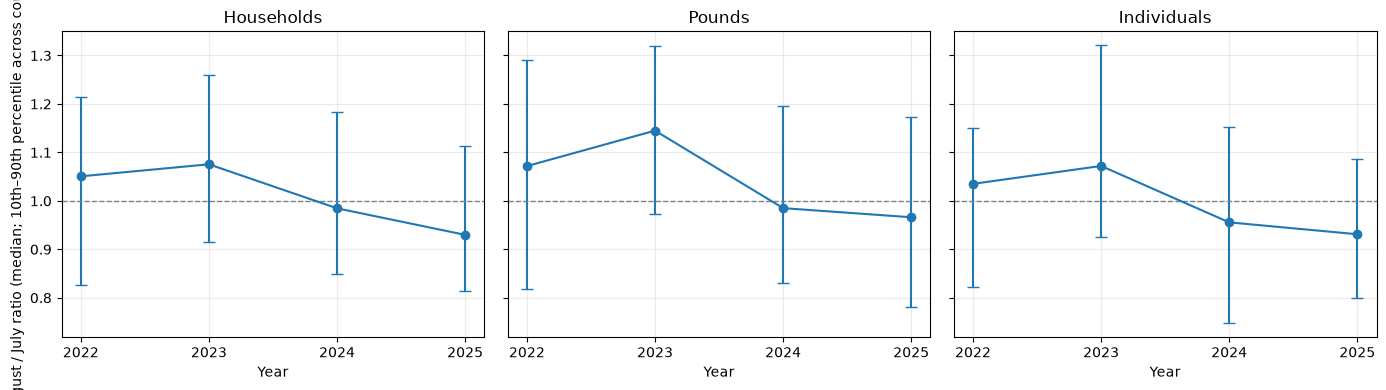

In [5]:
# County-level August/July ratios vary substantially; summarize by metric and year.
ratio_rows = []
for year in range(2022, 2026):
    july = panel.loc[panel.yearmonth.eq(year * 100 + 7), ["fips", *metrics]].set_index("fips")
    august = panel.loc[panel.yearmonth.eq(year * 100 + 8), ["fips", *metrics]].set_index("fips")
    ratios = august.div(july.where(july.gt(0))).replace([np.inf, -np.inf], np.nan)
    for metric in metrics:
        values = ratios[metric].dropna()
        ratio_rows.append({
            "year": year, "metric": metric, "counties": len(values),
            "median_ratio": values.median(),
            "q10_ratio": values.quantile(0.10),
            "q90_ratio": values.quantile(0.90),
        })
ratio_summary = pd.DataFrame(ratio_rows)
display(ratio_summary.loc[ratio_summary.metric.isin(cfg.THREE_METRICS)].round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, metric in zip(axes, cfg.THREE_METRICS):
    subset = ratio_summary.loc[ratio_summary.metric.eq(metric)]
    ax.errorbar(subset.year, subset.median_ratio,
                yerr=[subset.median_ratio - subset.q10_ratio,
                      subset.q90_ratio - subset.median_ratio],
                fmt="o-", capsize=4)
    ax.axhline(1, color="0.5", linestyle="--", linewidth=1)
    ax.set(title=metric.title(), xlabel="Year", xticks=range(2022, 2026))
    ax.grid(alpha=0.25)
axes[0].set_ylabel("August / July ratio (median; 10th–90th percentile across counties)")
fig.tight_layout()
plt.show()

## Historical seasonality and reporting composition

These descriptive checks use only the permitted panel. They help explain why the forecast should be treated as a forecast of **reported activity**: monthly totals can shift with both service volume and the number of sites reporting. August 2026 is not included in any input or calculation.

,households,pounds,individuals,children,adults,seniors
calendar_month,,,,,,
1,0.928,0.942,0.933,0.939,0.936,0.903
2,0.970,0.909,0.939,0.942,0.947,0.894
3,1.003,0.994,1.016,1.005,1.026,1.003
4,1.007,0.986,1.016,1.009,1.025,1.002
5,0.982,0.973,0.990,0.993,0.986,1.005
6,0.997,0.990,0.998,1.009,0.990,1.000
7,1.010,1.018,1.010,1.016,1.002,1.023
8,1.023,1.057,1.021,1.038,1.007,1.038
9,0.998,0.988,0.988,0.972,0.994,1.009


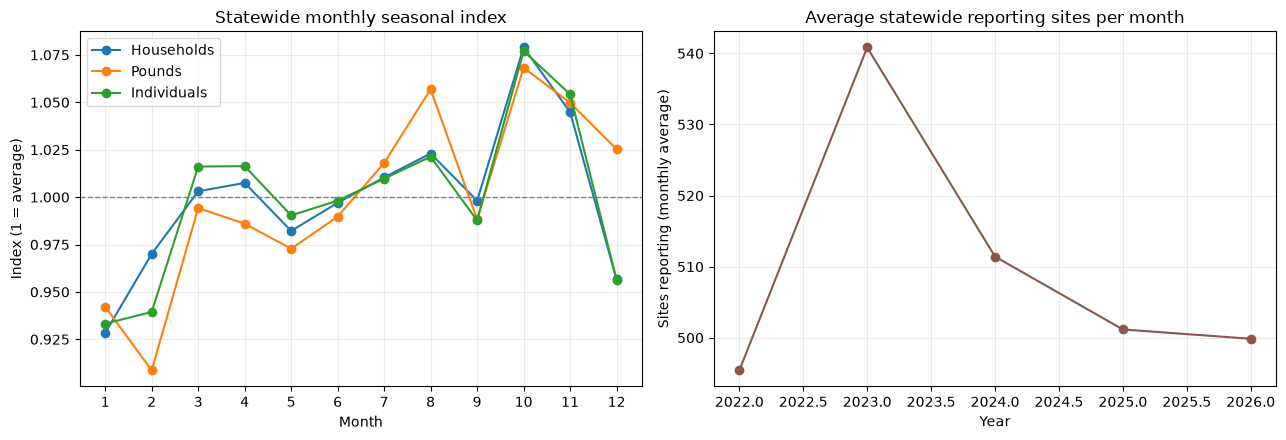

In [6]:
forecast_metrics = [*cfg.THREE_METRICS, *cfg.AGE_METRICS]
state_month = panel.groupby(["year", "month"], as_index=False)[forecast_metrics + ["n_sites_reporting"]].sum()
seasonality = state_month.groupby("month")[forecast_metrics].mean()
seasonality = seasonality.div(seasonality.mean(axis=0), axis="columns")
seasonality.index.name = "calendar_month"
display(seasonality.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for metric in cfg.THREE_METRICS:
    axes[0].plot(seasonality.index, seasonality[metric], marker="o", label=metric.title())
axes[0].axhline(1, color="0.5", linestyle="--", linewidth=1)
axes[0].set(title="Statewide monthly seasonal index", xlabel="Month", ylabel="Index (1 = average)", xticks=range(1, 13))
axes[0].legend()

site_counts = state_month.groupby("year", as_index=False)["n_sites_reporting"].mean()
axes[1].plot(site_counts["year"], site_counts["n_sites_reporting"], marker="o", color="#8c564b")
axes[1].set(title="Average statewide reporting sites per month", xlabel="Year", ylabel="Sites reporting (monthly average)")
axes[1].grid(alpha=0.25)
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Run the leakage-safe backtests and forecast

The script compares six candidates: seasonal naive, county August/July ratio, seasonal naive with drift, a ratio pooled toward the statewide median, a pooled trailing-quarter ratio using the mean of May–July, and a per-reporting-site ratio. It selects separately by outcome using average county-level RMSE across the three folds, matching the draft graduate rubric; WAPE, sMAPE and MAE remain diagnostics. The quarter method estimates its seasonal ratio from prior Augusts relative to the May–July mean, then applies that ratio to the current May–July average.

In [7]:
import runpy

analysis_path = ROOT / "questions" / "q7_forecast_august" / "analysis.py"
runpy.run_path(str(analysis_path), run_name="__main__")

Q7 -- Backtest and forecast August 2026 activity
leakage_check passed: nothing at or after 202608


  -> outputs/tables/q7_backtest_predictions.csv  (9657 rows)
  -> outputs/tables/q7_backtest_scores.csv  (148 rows)
  -> outputs/tables/q7_method_selection.csv  (37 rows)
  -> outputs/tables/q7_forecasts.csv  (522 rows)
  -> outputs/tables/q7_uncertainty_calibration.csv  (6 rows)

Selected forecast methods:
     metric               selected_method
     adults          pooled_quarter_ratio
     adults rural_peer_rate_per_fi_person
   children          pooled_quarter_ratio
   children rural_peer_rate_per_fi_person
 households          pooled_quarter_ratio
 households rural_peer_rate_per_fi_person
individuals                 age_group_sum
individuals rural_peer_rate_per_fi_person
     pounds          pooled_quarter_ratio
     pounds rural_peer_rate_per_fi_person
    seniors          pooled_quarter_ratio
    seniors rural_peer_rate_per_fi_person

Lowest mean-fold RMSE candidate per metric; final Individuals uses age sum:
     metric               method  mean_fold_rmse  mean_fold_smape_pc

{'__name__': '__main__',
 '__doc__': '\nQ7 -- Backtest and forecast August 2026 county activity.\n\nRun from the repo root:\n    python questions/q7_forecast_august/analysis.py\n\nAll forecasts and backtests use the processed panel only. The leakage check is\ndeliberately run before any target selection; no August 2026 data is permitted.\n',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': '/Users/uddam/copilot-worktrees/MinneMUDAC/uddamchea-stunning-spork/questions/q7_forecast_august/analysis.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich t

In [8]:
table_dir = ROOT / "outputs" / "tables"
forecasts = pd.read_csv(table_dir / "q7_forecasts.csv", dtype={"fips": "string"})
backtest_predictions = pd.read_csv(table_dir / "q7_backtest_predictions.csv", dtype={"fips": "string"})
backtest_scores = pd.read_csv(table_dir / "q7_backtest_scores.csv")
method_selection = pd.read_csv(table_dir / "q7_method_selection.csv")
uncertainty = pd.read_csv(table_dir / "q7_uncertainty_calibration.csv")

display(method_selection.loc[method_selection.selected_for_forecast].sort_values("metric").reset_index(drop=True))

,metric,method,mean_fold_rmse,worst_fold_rmse,mean_fold_smape_pct,worst_fold_smape_pct,mean_fold_wape_pct,mean_fold_mae,backtest_folds,selected_for_forecast
0,adults,pooled_quarter_ratio,1561.923784,1863.276688,12.922394,14.337169,8.903986,393.454638,3,True
1,children,pooled_quarter_ratio,1379.697371,1562.177717,17.505968,18.926441,11.869507,364.855322,3,True
2,households,pooled_quarter_ratio,971.517147,1406.069795,12.461109,13.315579,9.401758,258.847439,3,True
3,individuals,age_group_sum,2937.122848,3040.674834,12.627729,13.804978,9.147795,771.404145,3,True
4,pounds,pooled_quarter_ratio,52130.258655,73975.050256,14.874386,16.423835,10.647960,16009.686062,3,True
5,seniors,pooled_quarter_ratio,264.581184,408.822122,14.546955,15.863615,9.491764,89.662079,3,True


## Build the grading submission CSV

Run this cell after the forecast and backtest cell above. It reads the grading template and current August 2026 forecasts, fills the five scored prediction columns for all 87 named counties, validates that every county/metric has one nonblank forecast, and writes the completed template to `outputs/prediction/Graduate_Predictions_Submit.csv`. Values are rounded to whole units. The team ID field is preserved from the template and remains blank for you to fill in. Wilkin is filled using the documented rural-peer imputation; it is not a county-specific statistical forecast.

In [9]:
template_path = ROOT / "data" / "raw" / "reference" / "Graduate_Predictions_Submit.csv"
submission_path = ROOT / "outputs" / "prediction" / "Graduate_Predictions_Submit.csv"
submission_columns = {
    "households": "HouseholdReg_Predicted",
    "pounds": "PoundsReg_Predicted",
    "children": "ChildrenReg_Predicted",
    "seniors": "SeniorsReg_Predicted",
    "adults": "AdultsReg_Predicted",
}

def county_key(name):
    return " ".join(str(name).strip().casefold().split())

submission = pd.read_csv(template_path, dtype=str, keep_default_na=False)
required_template_columns = {"RowID", "County", "YourTeamID", *submission_columns.values()}
if not required_template_columns.issubset(submission.columns):
    raise ValueError(f"Grading template is missing columns: {required_template_columns - set(submission.columns)}")

named_rows = submission["County"].str.strip().ne("")
template_counties = submission.loc[named_rows, "County"].str.strip()
if template_counties.map(county_key).duplicated().any():
    raise ValueError("Grading template contains duplicate named counties")
if len(template_counties) != 87:
    raise ValueError(f"Expected 87 named Minnesota counties, found {len(template_counties)}")

required_forecasts = forecasts.loc[
    forecasts.metric.isin(submission_columns)
    & forecasts.target_yearmonth.eq(cfg.FORECAST_TARGET_YM)
].copy()
required_forecasts["county_key"] = required_forecasts.county_name.map(county_key)
if required_forecasts.duplicated(["county_key", "metric"]).any():
    raise ValueError("Forecast table has duplicate county/metric predictions")
forecast_counties = set(required_forecasts.county_key)
template_keys = set(template_counties.map(county_key))
if template_keys != forecast_counties:
    raise ValueError(
        f"Template/forecast county mismatch; missing={sorted(template_keys - forecast_counties)}, "
        f"extra={sorted(forecast_counties - template_keys)}"
    )
if not required_forecasts.forecast_status.isin(
    ["forecasted", "imputed_rural_peer_rate"]
).all():
    raise ValueError("A required county has no forecast or documented imputation")

lookup = required_forecasts.set_index(["county_key", "metric"])
for row_index in submission.index[named_rows]:
    key = county_key(submission.at[row_index, "County"])
    for metric, column in submission_columns.items():
        result = lookup.loc[(key, metric)]
        value = pd.to_numeric(result.prediction, errors="coerce")
        if pd.isna(value) or value < 0:
            raise ValueError(f"Invalid {metric} prediction for {submission.at[row_index, 'County']}")
        submission.at[row_index, column] = str(int(np.floor(value + 0.5)))

submission_path.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(submission_path, index=False)
submission_preview = submission.loc[
    named_rows, ["RowID", "County", *submission_columns.values()]
].copy()
display(submission_preview.reset_index(drop=True))
print(f"Saved {len(submission_preview)} county rows to {submission_path.relative_to(ROOT)}")
print("YourTeamID remains as supplied by the template; fill it in before uploading.")
imputed_counties = required_forecasts.loc[
    required_forecasts.forecast_status.eq("imputed_rural_peer_rate"), "county_name"
].drop_duplicates().tolist()
if imputed_counties:
    print("Rural-peer imputation (not county-specific model forecasts): " + ", ".join(imputed_counties))

,RowID,County,HouseholdReg_Predicted,PoundsReg_Predicted,ChildrenReg_Predicted,SeniorsReg_Predicted,AdultsReg_Predicted
0,1,Aitkin,514,23942,209,397,510
1,2,Anoka,17093,820319,27902,5938,34650
2,3,Becker,543,44705,511,255,959
3,4,Beltrami,1525,100508,1399,643,2425
4,5,Benton,781,32405,510,410,980
...,...,...,...,...,...,...,...
82,83,Watonwan,494,34632,775,129,1186
83,84,Wilkin,200,11491,183,74,299
84,85,Winona,1458,61186,766,545,1858
85,86,Wright,2430,217892,3189,1064,3897


Saved 87 county rows to outputs/prediction/Graduate_Predictions_Submit.csv
YourTeamID remains as supplied by the template; fill it in before uploading.
Rural-peer imputation (not county-specific model forecasts): Wilkin


## Backtest performance

The plot shows county-level sMAPE by backtest target. Lower is better. Compare fold-level performance as well as the average: there are only three backtest Augusts, so this is limited evidence, and a good average does not guarantee a good result in 2026.

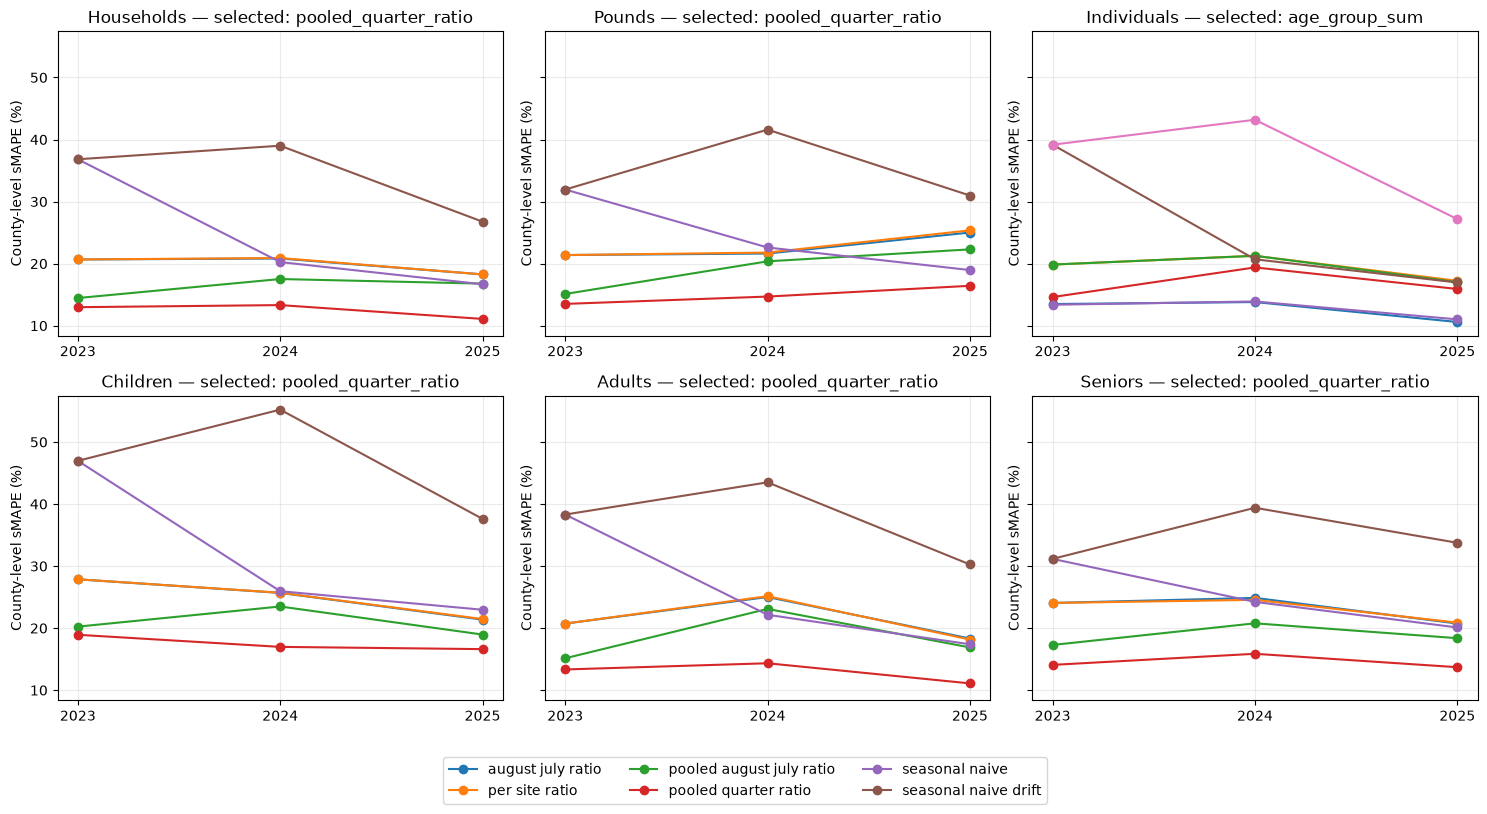

,metric,method,macro_smape_pct,wape_pct,mae
3,adults,pooled_quarter_ratio,12.92,8.90,393.45
2,adults,pooled_august_july_ratio,18.37,11.70,517.51
1,adults,per_site_ratio,21.34,12.76,565.77
0,adults,august_july_ratio,21.36,12.98,575.40
4,adults,seasonal_naive,25.95,18.23,798.29
5,adults,seasonal_naive_drift,37.35,34.06,1513.35
9,children,pooled_quarter_ratio,17.51,11.87,364.86
8,children,pooled_august_july_ratio,20.90,13.62,417.93
6,children,august_july_ratio,24.97,15.45,472.64
7,children,per_site_ratio,25.01,15.20,465.31


In [10]:
score_folds = backtest_scores.loc[backtest_scores["target_year"].ne("ALL")].copy()
score_folds["target_year"] = score_folds["target_year"].astype(int)
metrics_to_plot = [*cfg.THREE_METRICS, *cfg.AGE_METRICS]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, metric in zip(axes.flat, metrics_to_plot):
    subset = score_folds.loc[score_folds.metric.eq(metric)]
    for method, group in subset.groupby("method"):
        ax.plot(group.target_year, group.macro_smape_pct, marker="o", label=method.replace("_", " "))
    selected = method_selection.loc[method_selection.metric.eq(metric) & method_selection.selected_for_forecast, "method"]
    ax.set_title(f"{metric.title()} — selected: {selected.iloc[0] if len(selected) else 'n/a'}")
    ax.set_xticks([2023, 2024, 2025])
    ax.set_ylabel("County-level sMAPE (%)")
    ax.grid(alpha=0.25)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

display(
    score_folds.groupby(["metric", "method"], as_index=False)[["macro_smape_pct", "wape_pct", "mae"]]
    .mean().sort_values(["metric", "macro_smape_pct"]).round(2)
)

### Rubric-aligned performance: county RMSE by scored outcome

The draft graduate rubric scores the five required forecast outcomes using county-level RMSE. This chart recomputes RMSE from each selected method's August 2023, 2024, and 2025 backtest predictions. Each panel has its own units and scale, so compare years within an outcome—not the heights across different outcomes. Lower RMSE is better.

,metric_label,target_year,counties,rmse
0,Adults,2023,86,1377.4
1,Adults,2024,86,1445.1
2,Adults,2025,86,1863.3
3,Children,2023,86,1562.2
4,Children,2024,86,1306.1
5,Children,2025,86,1270.8
6,Households (visits proxy),2023,86,749.6
7,Households (visits proxy),2024,86,758.9
8,Households (visits proxy),2025,86,1406.1
9,Pounds,2023,86,27061.5


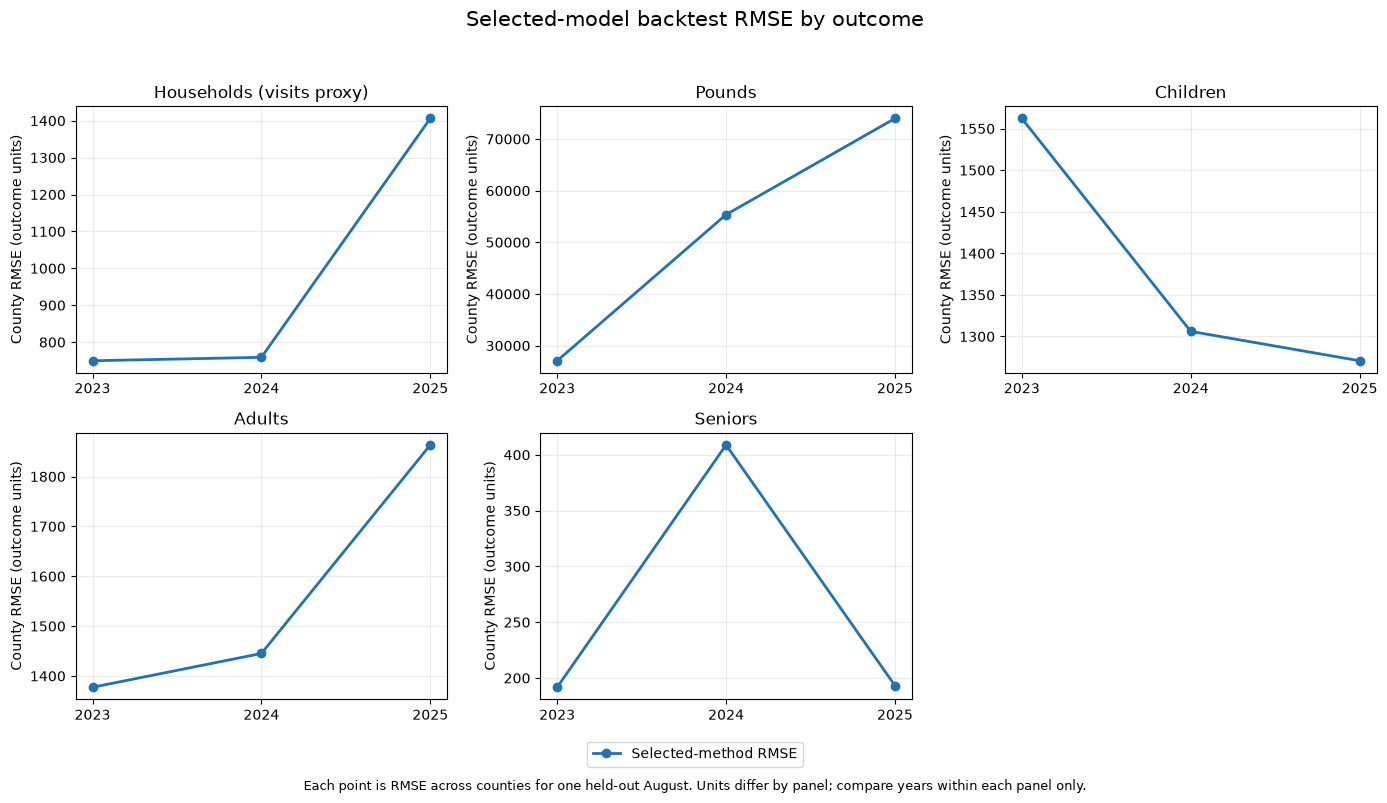

In [11]:
rubric_metrics = [cfg.M_VISITS, cfg.M_POUNDS, *cfg.AGE_METRICS]
selected_methods = method_selection.loc[
    method_selection.selected_for_forecast, ["metric", "method"]
]
selected_backtest = backtest_predictions.merge(
    selected_methods, on=["metric", "method"], how="inner", validate="m:1"
).dropna(subset=["actual", "prediction"])
selected_backtest = selected_backtest.loc[
    selected_backtest.metric.isin(rubric_metrics)
].copy()
selected_backtest["squared_error"] = (
    selected_backtest.prediction - selected_backtest.actual
) ** 2
rmse_by_fold = (
    selected_backtest.groupby(["metric", "target_year"], as_index=False)
    .agg(counties=("fips", "nunique"), mse=("squared_error", "mean"))
)
rmse_by_fold["rmse"] = np.sqrt(rmse_by_fold.mse)
rmse_by_fold["metric_label"] = rmse_by_fold.metric.map({
    cfg.M_VISITS: "Households (visits proxy)",
    cfg.M_POUNDS: "Pounds",
    "children": "Children",
    "adults": "Adults",
    "seniors": "Seniors",
})
display(rmse_by_fold[["metric_label", "target_year", "counties", "rmse"]]
        .sort_values(["metric_label", "target_year"]).round(1))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, metric in zip(axes.flat, rubric_metrics):
    subset = rmse_by_fold.loc[rmse_by_fold.metric.eq(metric)].sort_values("target_year")
    ax.plot(subset.target_year, subset.rmse, marker="o", linewidth=2, color="#2171b5", label="Selected-method RMSE")
    ax.set_title(subset.metric_label.iloc[0])
    ax.set_xticks([2023, 2024, 2025])
    ax.set_ylabel("County RMSE (outcome units)")
    ax.grid(alpha=0.25)
axes.flat[-1].set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.025))
fig.suptitle("Selected-model backtest RMSE by outcome", fontsize=15)
fig.text(0.5, 0.005,
         "Each point is RMSE across counties for one held-out August. Units differ by panel; compare years within each panel only.",
         ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.07, 1, 0.95))
plt.show()

### All candidate methods on the five rubric-scored outcomes

This chart compares the six candidate methods using **mean fold-level county RMSE** for households (the visits proxy), pounds, children, adults and seniors. Each gray bar is a method's average RMSE across the August 2023, 2024 and 2025 holdouts; colored dots show its RMSE in each individual year. Orange marks the selected pooled May–July ratio. Lower RMSE is better, but scales differ by metric, so compare methods only within the same panel. Each fold covers 86 reporting counties; only three holdout years are available, so this is evidence for the choice, not a guarantee of future accuracy.

Saved chart to outputs/figures/q7_method_rmse_comparison.png


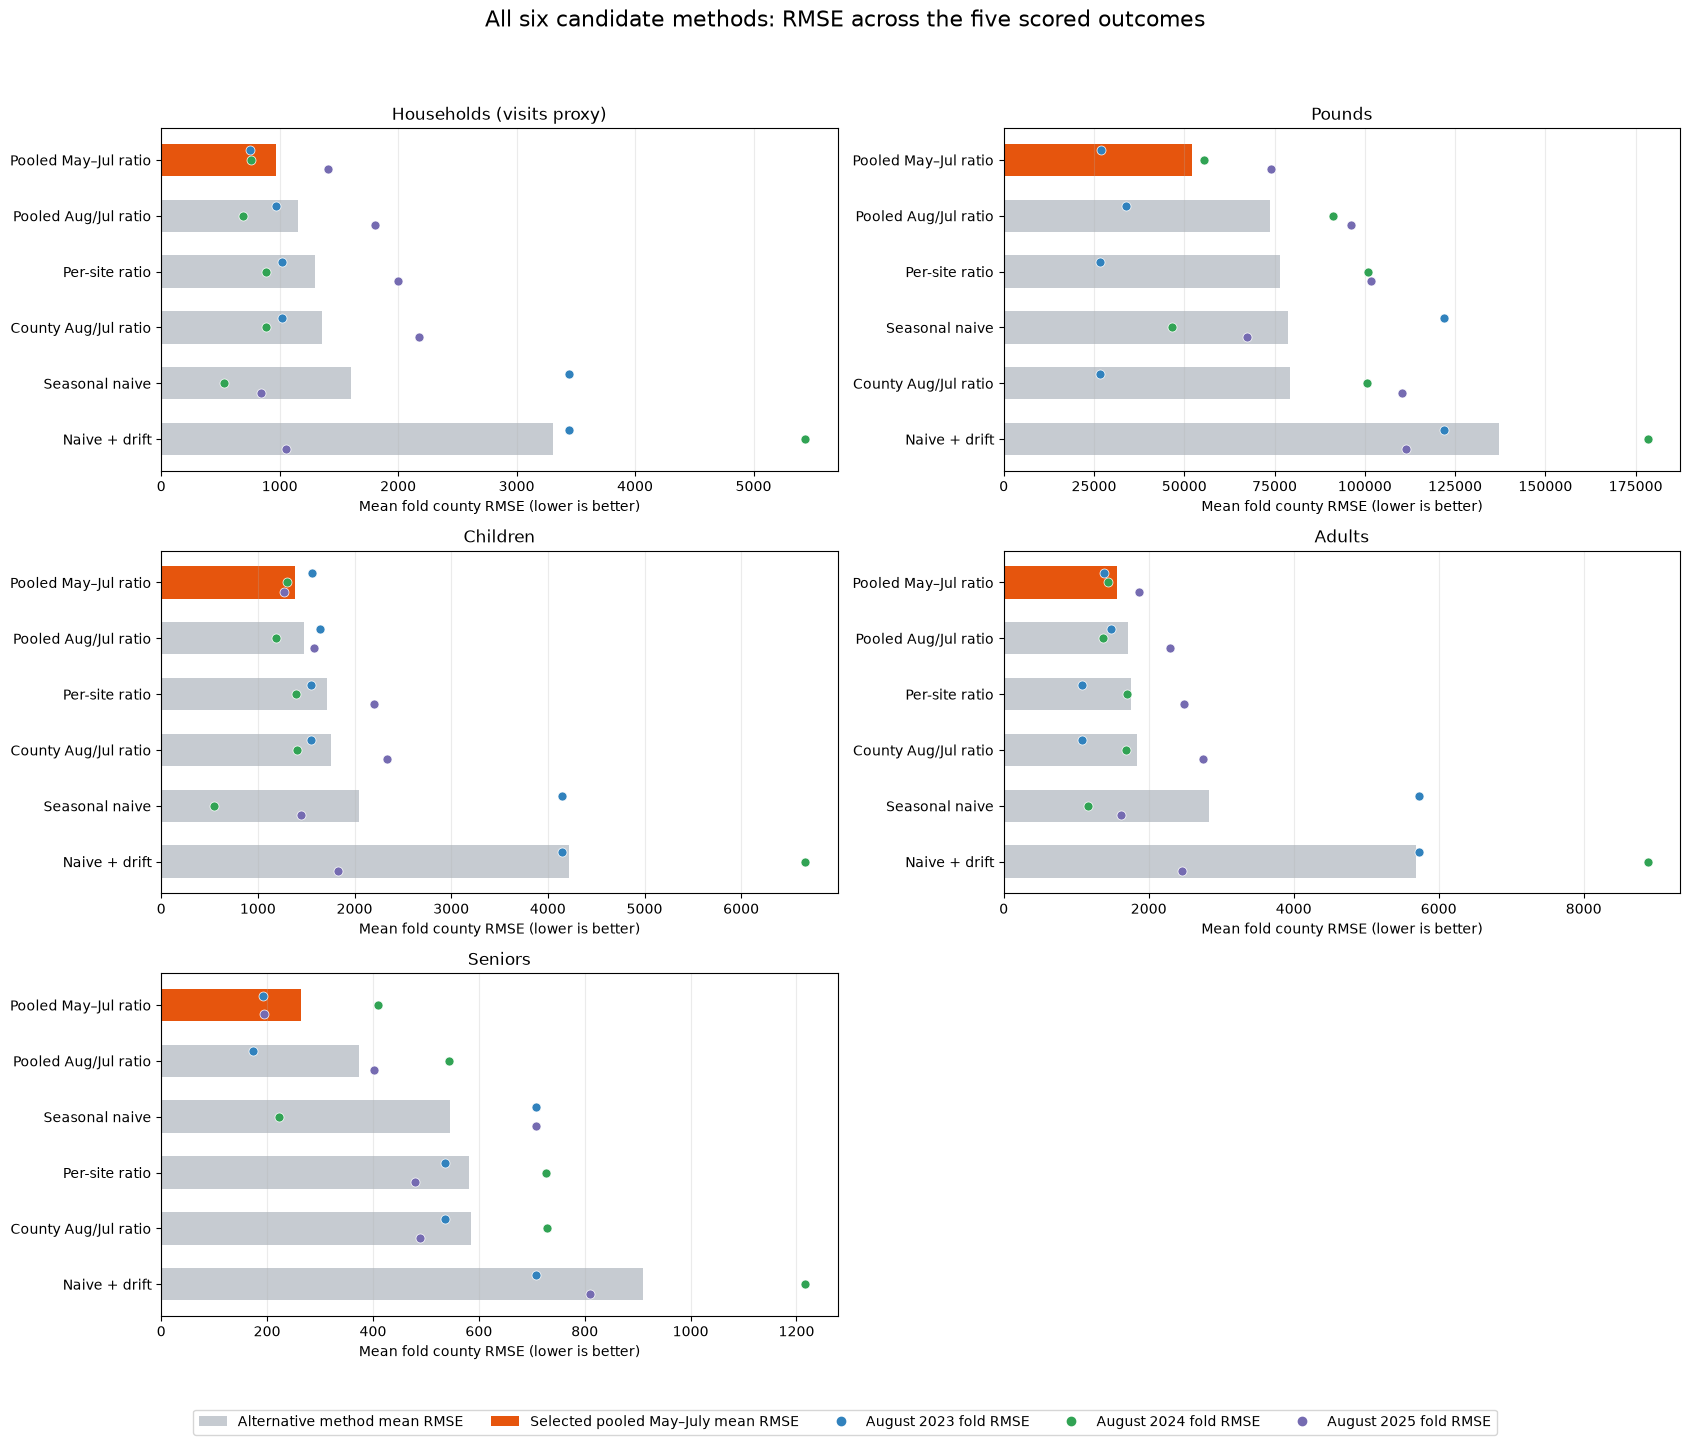

,Outcome,Selected method,Selected mean RMSE,Runner-up,Runner-up mean RMSE,RMSE reduction vs runner-up (%)
0,Households (visits proxy),Pooled May–Jul ratio,971.5,Pooled Aug/Jul ratio,1154.5,15.9
1,Pounds,Pooled May–Jul ratio,52130.3,Pooled Aug/Jul ratio,73769.6,29.3
2,Children,Pooled May–Jul ratio,1379.7,Pooled Aug/Jul ratio,1472.1,6.3
3,Adults,Pooled May–Jul ratio,1561.9,Pooled Aug/Jul ratio,1716.9,9.0
4,Seniors,Pooled May–Jul ratio,264.6,Pooled Aug/Jul ratio,372.9,29.0


In [12]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

rubric_metrics = [cfg.M_VISITS, cfg.M_POUNDS, *cfg.AGE_METRICS]
rubric_labels = {
    cfg.M_VISITS: "Households (visits proxy)",
    cfg.M_POUNDS: "Pounds",
    "children": "Children",
    "adults": "Adults",
    "seniors": "Seniors",
}
method_labels = {
    "seasonal_naive": "Seasonal naive",
    "august_july_ratio": "County Aug/Jul ratio",
    "seasonal_naive_drift": "Naive + drift",
    "pooled_august_july_ratio": "Pooled Aug/Jul ratio",
    "pooled_quarter_ratio": "Pooled May–Jul ratio",
    "per_site_ratio": "Per-site ratio",
}

fold_scores = backtest_scores.loc[
    backtest_scores.target_year.astype(str).ne("ALL")
    & backtest_scores.metric.isin(rubric_metrics)
].copy()
fold_scores["target_year"] = fold_scores["target_year"].astype(int)
method_scores = method_selection.loc[
    method_selection.metric.isin(rubric_metrics)
    & method_selection.method.isin(method_labels)
].copy()
assert method_scores.groupby("metric").size().eq(len(method_labels)).all()
assert method_scores.groupby("metric").selected_for_forecast.sum().eq(1).all()

fig, axes = plt.subplots(3, 2, figsize=(17, 15))
fold_colors = {2023: "#3182bd", 2024: "#31a354", 2025: "#756bb1"}
selected_color = "#e6550d"
other_color = "#c6cbd1"
for ax, metric in zip(axes.flat, rubric_metrics):
    summary = method_scores.loc[method_scores.metric.eq(metric)].sort_values(
        "mean_fold_rmse", ascending=True
    ).reset_index(drop=True)
    y = np.arange(len(summary))
    for pos, row in summary.iterrows():
        selected = bool(row.selected_for_forecast)
        ax.barh(
            pos,
            row.mean_fold_rmse,
            height=0.58,
            color=selected_color if selected else other_color,
            zorder=1,
        )
        by_year = fold_scores.loc[
            fold_scores.metric.eq(metric) & fold_scores.method.eq(row.method)
        ]
        for offset, year in zip((-0.17, 0, 0.17), (2023, 2024, 2025)):
            point = by_year.loc[by_year.target_year.eq(year), "rmse"]
            if not point.empty:
                ax.scatter(
                    point.iloc[0], pos + offset, s=42, color=fold_colors[year],
                    edgecolor="white", linewidth=0.5, zorder=3,
                )
    ax.set_yticks(y, [method_labels[m] for m in summary.method])
    ax.invert_yaxis()
    ax.set_title(rubric_labels[metric])
    ax.set_xlabel("Mean fold county RMSE (lower is better)")
    ax.grid(axis="x", alpha=0.25, zorder=0)
    ax.ticklabel_format(axis="x", style="plain")
axes.flat[-1].set_visible(False)
legend_handles = [
    Patch(facecolor=other_color, label="Alternative method mean RMSE"),
    Patch(facecolor=selected_color, label="Selected pooled May–July mean RMSE"),
    *[
        Line2D([0], [0], marker="o", linestyle="", color=color, label=f"August {year} fold RMSE")
        for year, color in fold_colors.items()
    ],
]
fig.legend(handles=legend_handles, loc="lower center", ncol=5, bbox_to_anchor=(0.5, 0.025))
fig.suptitle("All six candidate methods: RMSE across the five scored outcomes", fontsize=16)
fig.tight_layout(rect=(0, 0.07, 1, 0.95))
figure_path = ROOT / "outputs" / "figures" / "q7_method_rmse_comparison.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
print(f"Saved chart to {figure_path.relative_to(ROOT)}")
plt.show()

ranked = method_scores.sort_values(["metric", "mean_fold_rmse"]).copy()
ranked["rank"] = ranked.groupby("metric").cumcount() + 1
comparison_rows = []
for metric in rubric_metrics:
    candidates = ranked.loc[ranked.metric.eq(metric)].reset_index(drop=True)
    best, runner_up = candidates.iloc[0], candidates.iloc[1]
    comparison_rows.append({
        "Outcome": rubric_labels[metric],
        "Selected method": method_labels[best.method],
        "Selected mean RMSE": best.mean_fold_rmse,
        "Runner-up": method_labels[runner_up.method],
        "Runner-up mean RMSE": runner_up.mean_fold_rmse,
        "RMSE reduction vs runner-up (%)": 100 * (runner_up.mean_fold_rmse - best.mean_fold_rmse) / runner_up.mean_fold_rmse,
    })
comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round({
    "Selected mean RMSE": 1,
    "Runner-up mean RMSE": 1,
    "RMSE reduction vs runner-up (%)": 1,
}))

### Candidate methods versus actuals, plus the August 2026 forecast

For each outcome, compare statewide totals from each method with the actual statewide total in the held-out Augusts. The star is the final August 2026 forecast, summed across the 86 counties with reporting history. This aggregate view makes model behavior easy to compare, but errors can cancel across counties; use the county-level RMSE chart above for performance assessment. No August 2026 actual is included or sought.

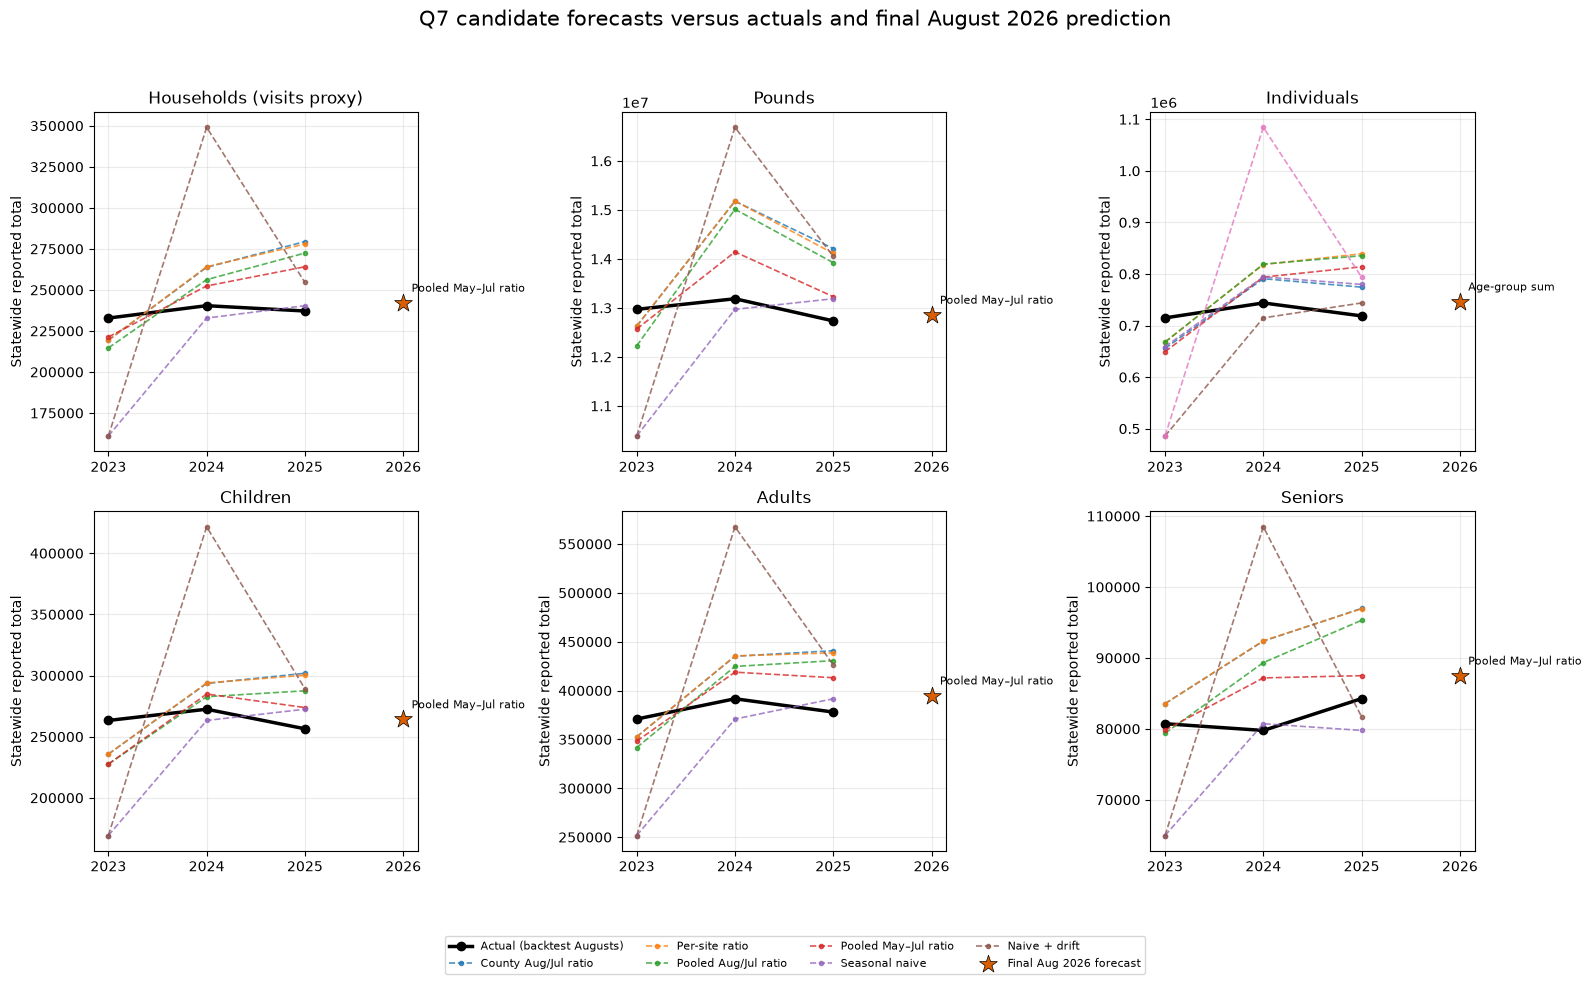

,metric,August 2026 forecast total,selected_method
0,adults,394810.0,Pooled May–Jul ratio
1,children,264116.0,Pooled May–Jul ratio
2,households (visits proxy),242106.0,Pooled May–Jul ratio
3,individuals,746409.0,Age-group sum
4,pounds,12857718.0,Pooled May–Jul ratio
5,seniors,87483.0,Pooled May–Jul ratio


In [13]:
actual_totals = (
    backtest_predictions[["target_year", "metric", "fips", "actual"]]
    .drop_duplicates(["target_year", "metric", "fips"])
    .groupby(["metric", "target_year"], as_index=False)
    .agg(actual_total=("actual", "sum"))
)
method_totals = (
    backtest_predictions.groupby(["metric", "target_year", "method"], as_index=False)
    .agg(predicted_total=("prediction", "sum"))
)
final_totals = forecasts.groupby("metric", as_index=False).agg(
    forecast_total=("prediction", "sum"),
    selected_method=("selected_method", "first"),
)

method_labels = {
    "seasonal_naive": "Seasonal naive",
    "august_july_ratio": "County Aug/Jul ratio",
    "seasonal_naive_drift": "Naive + drift",
    "pooled_august_july_ratio": "Pooled Aug/Jul ratio",
    "pooled_quarter_ratio": "Pooled May–Jul ratio",
    "per_site_ratio": "Per-site ratio",
    "age_group_sum": "Age-group sum",
}
plot_metrics = [*cfg.THREE_METRICS, *cfg.AGE_METRICS]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, metric in zip(axes.flat, plot_metrics):
    actual = actual_totals.loc[actual_totals.metric.eq(metric)].sort_values("target_year")
    ax.plot(actual.target_year, actual.actual_total, color="black", marker="o",
            linewidth=2.5, label="Actual (backtest Augusts)")
    candidates = method_totals.loc[method_totals.metric.eq(metric)]
    for method, group in candidates.groupby("method"):
        group = group.sort_values("target_year")
        ax.plot(group.target_year, group.predicted_total, marker=".", linewidth=1.2,
                linestyle="--", alpha=0.8,
                label=method_labels.get(method, method.replace("_", " ")))
    final = final_totals.loc[final_totals.metric.eq(metric)].iloc[0]
    ax.scatter([2026], [final.forecast_total], marker="*", s=180,
               color="#d95f02", edgecolor="black", linewidth=0.5,
               zorder=5, label="Final Aug 2026 forecast")
    ax.annotate(method_labels.get(final.selected_method, final.selected_method),
                (2026, final.forecast_total), xytext=(6, 8),
                textcoords="offset points", fontsize=8)
    ax.set_title(metric.title() + (" (visits proxy)" if metric == cfg.M_VISITS else ""))
    ax.set_xticks([2023, 2024, 2025, 2026])
    ax.set_ylabel("Statewide reported total")
    ax.grid(alpha=0.25)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, 0.01), fontsize=8)
fig.suptitle("Q7 candidate forecasts versus actuals and final August 2026 prediction", fontsize=15)
fig.tight_layout(rect=(0, 0.1, 1, 0.95))
plt.show()

display(final_totals.assign(
    metric=final_totals.metric.replace({cfg.M_VISITS: "households (visits proxy)"}),
    forecast_total=final_totals.forecast_total.round(0),
    selected_method=final_totals.selected_method.map(
        lambda method: method_labels.get(method, method)
    ),
).rename(columns={"forecast_total": "August 2026 forecast total"}))

## Final August 2026 prediction and empirical uncertainty range

This is the final point forecast from the selected methods. The county reference includes all 87 counties: 86 have reporting history and Wilkin uses a separately labeled rural-peer imputation, not zero. The county chart labels the ten largest predictions in each metric. The lower and upper columns for modeled counties are the 10th and 90th percentile empirical-error ranges from the selected method's backtests. They are **not calibrated guarantees**; only three target years are available. The submission export cell below the loaded forecast tables writes the grading-template CSV.

,metric,counties_in_output,counties_forecasted,august_2026_point_forecast_sum,selected_method
0,adults,87,87,394809.7,pooled_quarter_ratio
1,children,87,87,264115.5,pooled_quarter_ratio
2,households,87,87,242105.7,pooled_quarter_ratio
3,individuals,87,87,746408.7,age_group_sum
4,pounds,87,87,12857718.2,pooled_quarter_ratio
5,seniors,87,87,87483.4,pooled_quarter_ratio


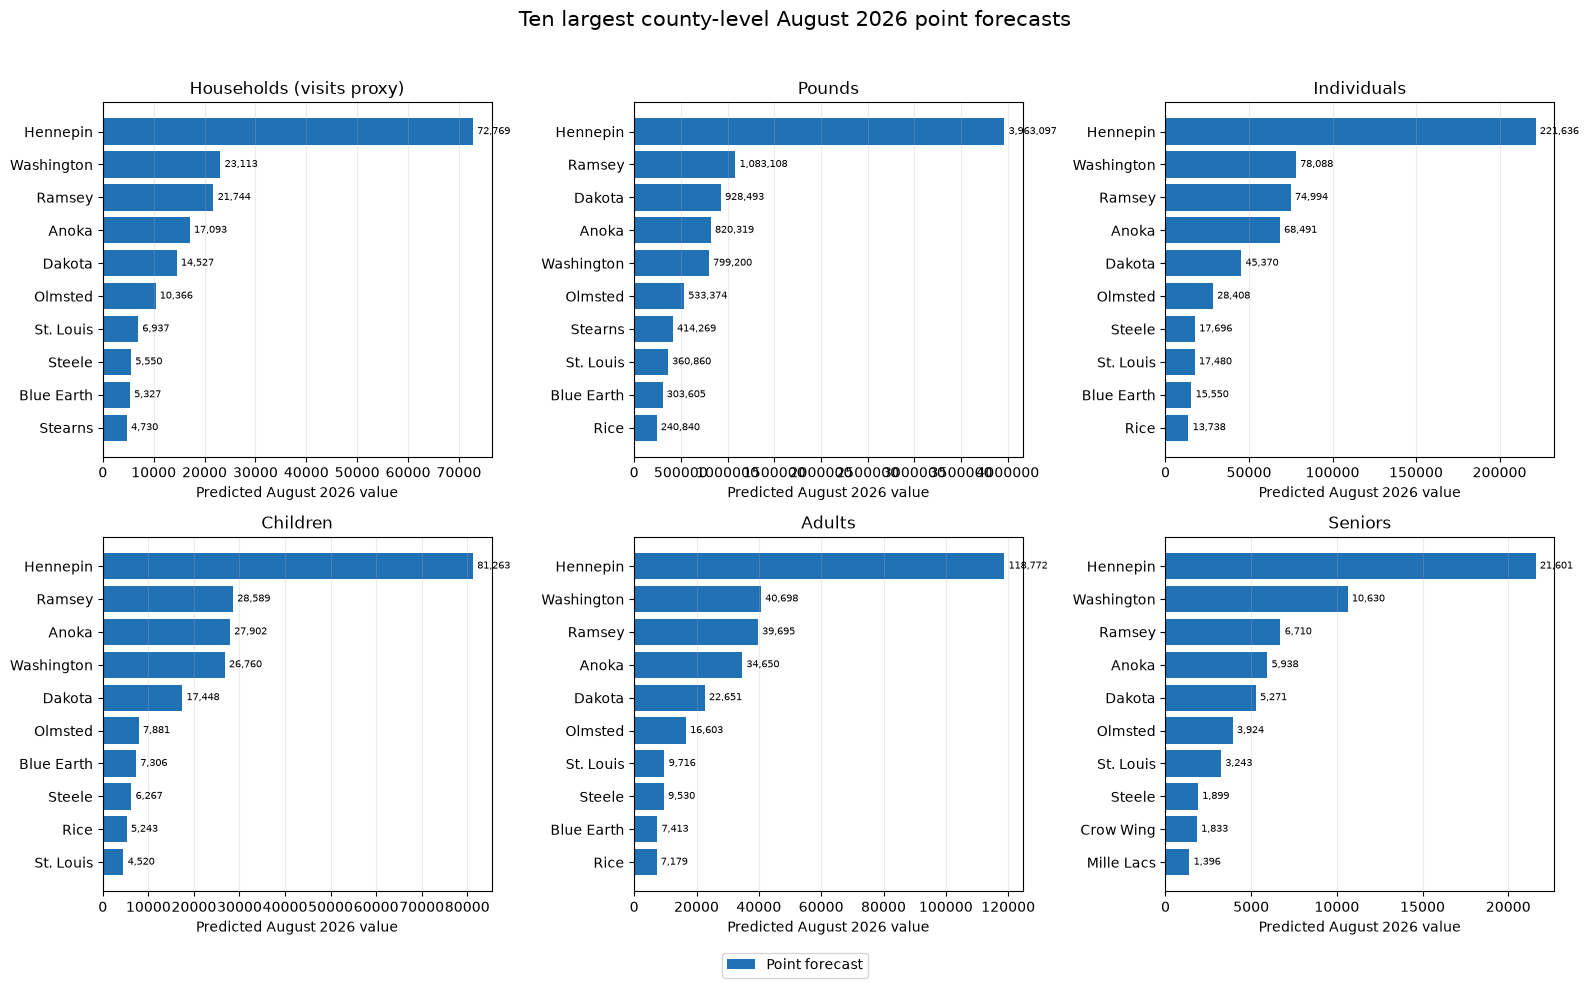

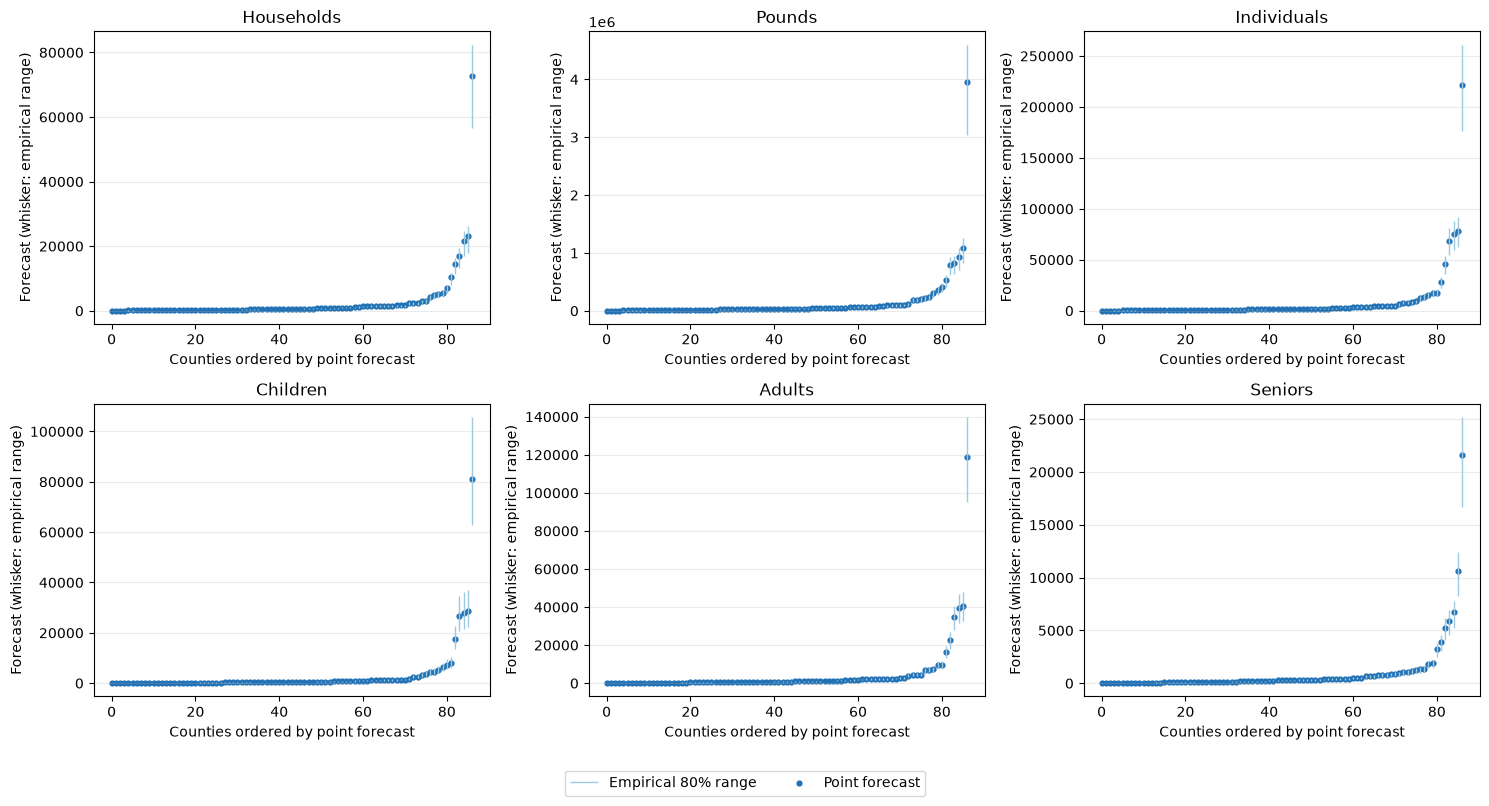

,fips,county_name,metric,forecast_status


In [14]:
display(
    forecasts.groupby("metric", as_index=False).agg(
        counties_in_output=("fips", "nunique"),
        counties_forecasted=("prediction", "count"),
        august_2026_point_forecast_sum=("prediction", "sum"),
        selected_method=("selected_method", "first"),
    ).round(1).sort_values("metric")
)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, metric in zip(axes.flat, metrics_to_plot):
    subset = (forecasts.loc[forecasts.metric.eq(metric) & forecasts.prediction.notna()]
              .nlargest(10, "prediction").sort_values("prediction"))
    bars = ax.barh(subset.county_name, subset.prediction, color="#2171b5", label="Point forecast")
    ax.bar_label(bars, labels=[f"{value:,.0f}" for value in subset.prediction], padding=3, fontsize=7)
    ax.set_title(metric.title() + (" (visits proxy)" if metric == cfg.M_VISITS else ""))
    ax.set_xlabel("Predicted August 2026 value")
    ax.grid(axis="x", alpha=0.25)
    ax.ticklabel_format(axis="x", style="plain")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.005))
fig.suptitle("Ten largest county-level August 2026 point forecasts", fontsize=15)
fig.tight_layout(rect=(0, 0.04, 1, 0.96))
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, metric in zip(axes.flat, metrics_to_plot):
    subset = forecasts.loc[forecasts.metric.eq(metric) & forecasts.prediction.notna()].sort_values("prediction")
    x = np.arange(len(subset))
    ax.vlines(x, subset.lower_80, subset.upper_80, color="#9ecae1", linewidth=1, label="Empirical 80% range")
    ax.scatter(x, subset.prediction, s=12, color="#2171b5", label="Point forecast")
    ax.set_title(metric.title())
    ax.set_xlabel("Counties ordered by point forecast")
    ax.set_ylabel("Forecast (whisker: empirical range)")
    ax.grid(axis="y", alpha=0.25)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

display(forecasts.loc[forecasts.forecast_status.eq("no_reporting_history"), ["fips", "county_name", "metric", "forecast_status"]])

## Graduate age-group checks

Individuals is derived county-by-county as children + adults + seniors. The table also flags forecasts whose age share falls outside that county's historical monthly range; these are reviewed rather than silently clipped. The range flag is a diagnostic, not a hard modeling constraint.

In [15]:
age_forecasts = forecasts.loc[forecasts.metric.isin(cfg.AGE_METRICS)].copy()
age_share_flags = age_forecasts.loc[
    age_forecasts.age_share_within_historical_range.eq(False),
    ["fips", "county_name", "metric", "prediction", "age_share_forecast",
     "age_share_historical_min", "age_share_historical_max"],
].sort_values(["metric", "county_name"])
display(age_share_flags.round(3))

wide_forecast = forecasts.pivot(index="fips", columns="metric", values="prediction")
age_sum = wide_forecast[cfg.AGE_METRICS].sum(axis=1, min_count=3)
if not np.allclose(wide_forecast[cfg.M_INDIVIDUALS].dropna(), age_sum.dropna()):
    raise ValueError("Derived Individuals does not reconcile to the age-group forecasts")
print("Age-group sum check passed for every county with a forecast.")
print(f"Counties with at least one age-share range flag: {age_share_flags.fips.nunique()}")

,fips,county_name,metric,prediction,age_share_forecast,age_share_historical_min,age_share_historical_max
468,27157,Wabasha,adults,2152.333,0.579,0.477,0.579
469,27157,Wabasha,children,1083.171,0.292,0.293,0.365
299,27099,Mower,seniors,756.841,0.175,0.073,0.173


Age-group sum check passed for every county with a forecast.
Counties with at least one age-share range flag: 2


## Interpretation and limitations

- Reported activity reflects both service demand and which organizations submitted data; July 2026's reporting-site count may still be incomplete.
- County-level data rolls up Hennepin and Ramsey to whole counties. It cannot produce split forecasts from this panel.
- Wilkin has no reporting history; its submitted values are an explicitly labeled rural-peer rate imputation based on activity per food-insecure person, not a county-specific forecast.
- The selected pooled-quarter method ranked best in only three backtest folds; do not present this as proof it will be most accurate in August 2026.
- A person other than the model author must complete the repository-wide leakage audit before submission.

The submission export cell writes `outputs/prediction/Graduate_Predictions_Submit.csv` from the grading template and the current `outputs/tables/q7_forecasts.csv`. Re-run this notebook top to bottom to refresh the forecasts and submission file.